In [1]:

from google.colab import files
uploaded = files.upload()


Saving customer_churn_cleaned.csv to customer_churn_cleaned.csv


In [2]:

import pandas as pd

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nChurn Values:")
print(df["Churn"].value_counts(dropna=False))

df.head()


Dataset Shape: (600, 13)

Column Names:
['customerid', 'age', 'region', 'tenuremonths', 'subscriptiontype', 'monthlychargesinr', 'totalchargesinr', 'contracttype', 'supporttickets', 'latepayments', 'paymentmethod', 'autopay', 'churn']

Churn Values:


KeyError: 'Churn'

In [3]:

# Check churn values
print("Churn values:")
print(df["churn"].value_counts(dropna=False))

# Check monthly charges
print("\nMonthly Charges Summary:")
print(df["monthlychargesinr"].describe())


Churn values:
churn
No     353
Yes    247
Name: count, dtype: int64

Monthly Charges Summary:
count      600.000000
mean       869.032833
std       1109.118011
min        364.340000
25%        451.557500
50%        726.105000
75%       1103.502500
max      13858.560000
Name: monthlychargesinr, dtype: float64


In [4]:

import pandas as pd

# Check churn values first
print("Churn values:")
print(df["Churn"].value_counts(dropna=False))

print("\nMonthly Charges summary:")
print(df["MonthlyChargesINR"].describe())


Churn values:


KeyError: 'Churn'

In [5]:

# Remove extra spaces from column names
df.columns = df.columns.str.strip().str.lower()

# Display exact column names
print(df.columns.tolist())

# Check churn values
print(df["churn"].value_counts(dropna=False))

# Check monthly charges
print(df["monthlychargesinr"].describe())


['customerid', 'age', 'region', 'tenuremonths', 'subscriptiontype', 'monthlychargesinr', 'totalchargesinr', 'contracttype', 'supporttickets', 'latepayments', 'paymentmethod', 'autopay', 'churn']
churn
No     353
Yes    247
Name: count, dtype: int64
count      600.000000
mean       869.032833
std       1109.118011
min        364.340000
25%        451.557500
50%        726.105000
75%       1103.502500
max      13858.560000
Name: monthlychargesinr, dtype: float64


In [6]:

# 1. Churn Rate
total_customers = len(df)
churned_customers = (df["churn"].str.strip().str.lower() == "yes").sum()

churn_rate = (churned_customers / total_customers) * 100

# 2. Monthly Recurring Revenue (MRR) Loss
df["monthlychargesinr"] = pd.to_numeric(
    df["monthlychargesinr"], errors="coerce"
)

churned_df = df[
    df["churn"].str.strip().str.lower() == "yes"
]

mrr_loss = churned_df["monthlychargesinr"].sum()

# 3. Estimated CLV
# Simple estimate: average monthly charges × average tenure
avg_monthly_charges = df["monthlychargesinr"].mean()
avg_tenure = df["tenuremonths"].mean()

estimated_clv = avg_monthly_charges * avg_tenure

# Display results
print("===== CUSTOMER CHURN ANALYSIS =====")
print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Estimated MRR Loss: ₹{mrr_loss:,.2f}")
print(f"Estimated CLV: ₹{estimated_clv:,.2f}")


===== CUSTOMER CHURN ANALYSIS =====
Total Customers: 600
Churned Customers: 247
Churn Rate: 41.17%
Estimated MRR Loss: ₹240,102.48
Estimated CLV: ₹30,886.88


===== CHURN BY CONTRACT TYPE =====
                total_customers  churned_customers  churn_rate_percent
contracttype                                                          
Month-to-Month              316                189               59.81
One Year                    164                 33               20.12
Two Year                    120                 25               20.83

===== CHURN BY TENURE =====
              total_customers  churned_customers  churn_rate_percent
tenure_group                                                        
0-12 months               104                 56               53.85
13-24 months              110                 50               45.45
25-48 months              188                 72               38.30
48+ months                198                 69               34.85

===== CHURN BY PAYMENT METHOD =====
               total_customers  churned_customers  churn_rate_percent
paymentmethod                                               

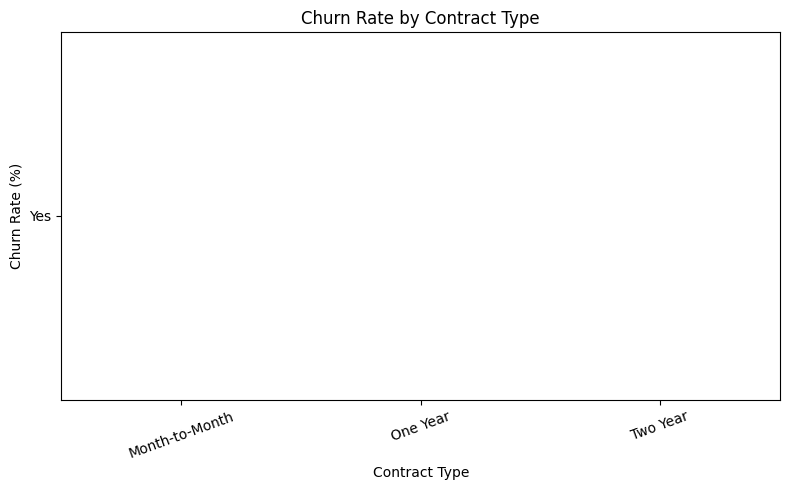

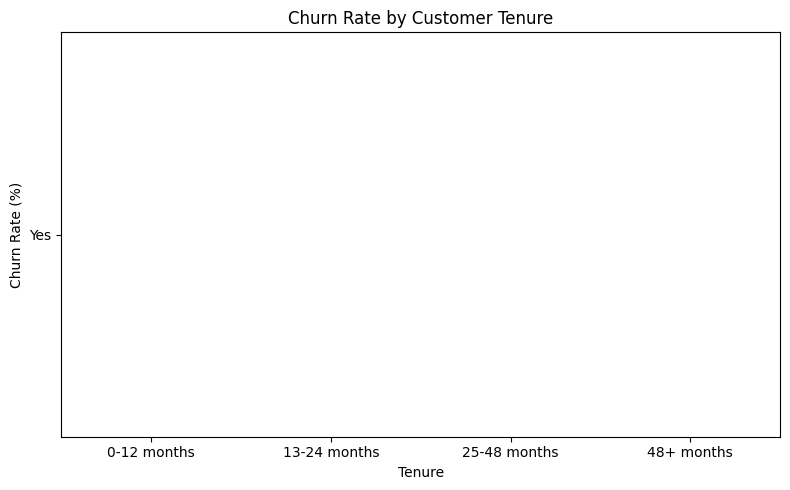

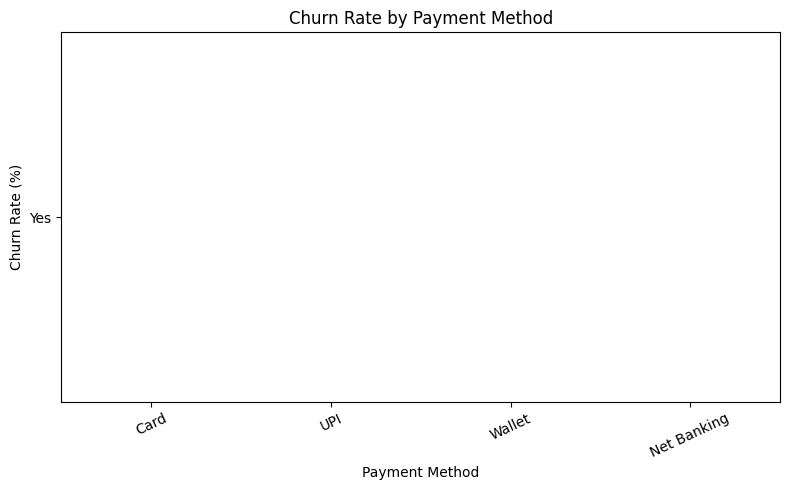

In [7]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Standardize churn values
df["churn"] = df["churn"].astype(str).str.strip().str.title()

# Create tenure groups
df["tenuremonths"] = pd.to_numeric(
    df["tenuremonths"], errors="coerce"
)

df["tenure_group"] = pd.cut(
    df["tenuremonths"],
    bins=[-1, 12, 24, 48, float("inf")],
    labels=["0-12 months", "13-24 months",
            "25-48 months", "48+ months"]
)

# Calculate churn percentage for each category
def churn_summary(column):
    result = df.groupby(column, observed=True).agg(
        total_customers=("churn", "size"),
        churned_customers=(
            "churn", lambda x: (x == "Yes").sum()
        )
    )
    result["churn_rate_percent"] = (
        result["churned_customers"] /
        result["total_customers"] * 100
    )
    return result.round(2)

print("===== CHURN BY CONTRACT TYPE =====")
print(churn_summary("contracttype"))

print("\n===== CHURN BY TENURE =====")
print(churn_summary("tenure_group"))

print("\n===== CHURN BY PAYMENT METHOD =====")
print(churn_summary("paymentmethod"))

# Plot 1: Contract type
plt.figure(figsize=(8, 5))
sns.barplot(
    data=df, x="contracttype", y="churn",
    estimator=lambda x: (x == "Yes").mean() * 100
)
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Plot 2: Tenure group
plt.figure(figsize=(8, 5))
sns.barplot(
    data=df, x="tenure_group", y="churn",
    estimator=lambda x: (x == "Yes").mean() * 100
)
plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

# Plot 3: Payment method
plt.figure(figsize=(8, 5))
sns.barplot(
    data=df, x="paymentmethod", y="churn",
    estimator=lambda x: (x == "Yes").mean() * 100
)
plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


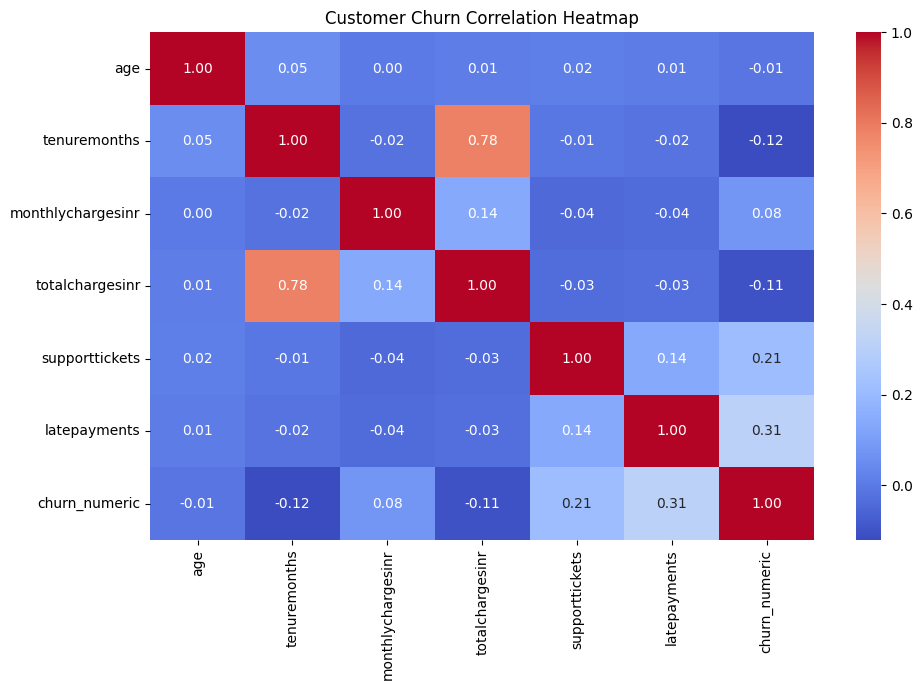

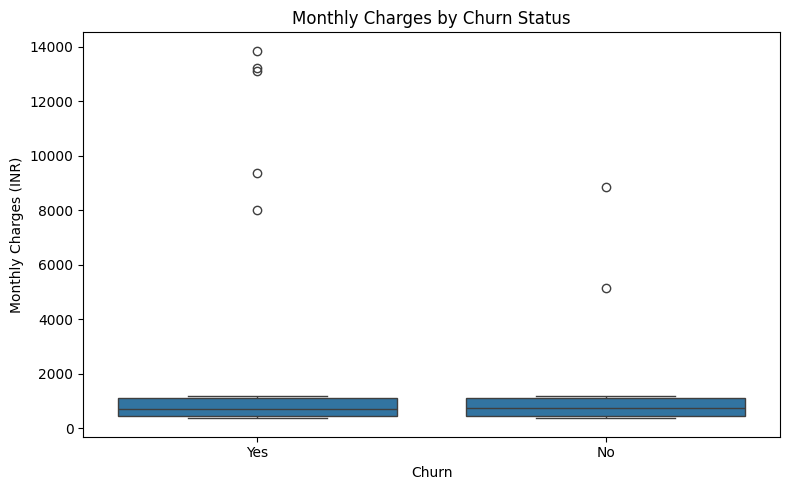

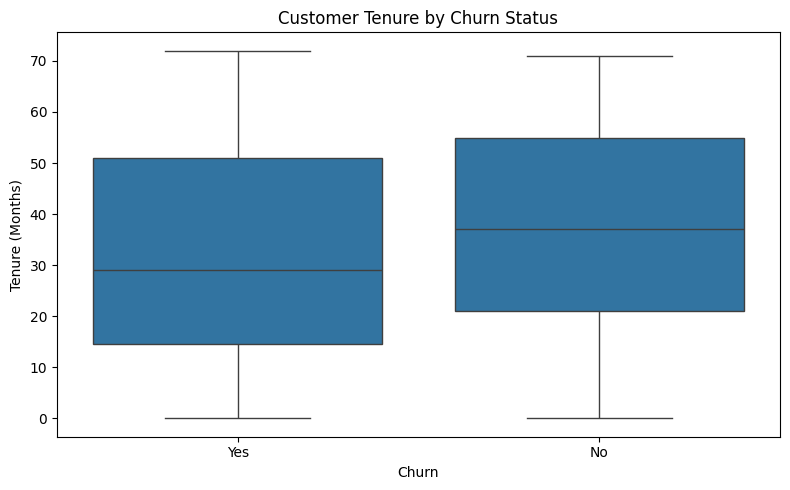

In [8]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert churn into numeric values for analysis
df["churn_numeric"] = df["churn"].map({"No": 0, "Yes": 1})

# Heatmap: numeric feature correlations
numeric_cols = [
    "age", "tenuremonths", "monthlychargesinr",
    "totalchargesinr", "supporttickets",
    "latepayments", "churn_numeric"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

plt.figure(figsize=(10, 7))
sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Customer Churn Correlation Heatmap")
plt.tight_layout()
plt.show()

# Boxplot: monthly charges by churn status
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="churn", y="monthlychargesinr")
plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges (INR)")
plt.tight_layout()
plt.show()

# Boxplot: tenure by churn status
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="churn", y="tenuremonths")
plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()


In [9]:

# Step 6: Actionable Recommendations

print("===== KEY FINDINGS =====")
print(f"Total Customers: {len(df)}")
print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Churned Customers: {churned_customers}")
print(f"Estimated MRR Loss: Rs. {mrr_loss:,.2f}")
print(f"Estimated CLV: Rs. {estimated_clv:,.2f}")

print("\n===== ACTIONABLE RECOMMENDATIONS =====")
print("1. Identify contract types with the highest churn rate.")
print("2. Provide onboarding support to new customers.")
print("3. Investigate payment methods associated with high churn.")
print("4. Contact at-risk customers and offer suitable retention plans.")
print("5. Monitor support tickets and late payments to identify service issues.")
print("6. Track churn rate and monthly revenue loss regularly.")


===== KEY FINDINGS =====
Total Customers: 600
Churn Rate: 41.17%
Churned Customers: 247
Estimated MRR Loss: Rs. 240,102.48
Estimated CLV: Rs. 30,886.88

===== ACTIONABLE RECOMMENDATIONS =====
1. Identify contract types with the highest churn rate.
2. Provide onboarding support to new customers.
3. Investigate payment methods associated with high churn.
4. Contact at-risk customers and offer suitable retention plans.
5. Monitor support tickets and late payments to identify service issues.
6. Track churn rate and monthly revenue loss regularly.


In [10]:

!pip -q install reportlab

from reportlab.lib.pagesizes import A4
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image as PDFImage
)
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
from reportlab.lib.units import inch
import matplotlib.pyplot as plt
import os

# Save charts from the current notebook
chart_files = []

for i, fig_num in enumerate(plt.get_fignums(), start=1):
    fig = plt.figure(fig_num)
    path = f"churn_chart_{i}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    chart_files.append(path)

pdf_name = "Customer_Churn_Analysis_Report.pdf"
doc = SimpleDocTemplate(
    pdf_name, pagesize=A4,
    rightMargin=40, leftMargin=40,
    topMargin=40, bottomMargin=40
)

styles = getSampleStyleSheet()
story = []

story.append(Paragraph(
    "Customer Churn Analysis Report",
    styles["Title"]
))
story.append(Spacer(1, 12))

story.append(Paragraph("1. Project Overview", styles["Heading2"]))
story.append(Paragraph(
    "This project analyzes customer churn, revenue loss, customer "
    "lifetime value estimates, and churn patterns across customer groups.",
    styles["BodyText"]
))
story.append(Spacer(1, 10))

story.append(Paragraph("2. Key Results", styles["Heading2"]))
results = [
    f"Total customers: {total_customers}",
    f"Churned customers: {churned_customers}",
    f"Churn rate: {churn_rate:.2f}%",
    f"Estimated MRR loss: Rs. {mrr_loss:,.2f}",
    f"Simplified estimated CLV: Rs. {estimated_clv:,.2f}"
]
for item in results:
    story.append(Paragraph(item, styles["BodyText"]))
    story.append(Spacer(1, 5))

story.append(Spacer(1, 10))
story.append(Paragraph("3. Visual Analysis", styles["Heading2"]))

for path in chart_files:
    story.append(Spacer(1, 8))
    story.append(PDFImage(path, width=6.2*inch, height=3.5*inch))

story.append(Spacer(1, 10))
story.append(Paragraph("4. Recommendations", styles["Heading2"]))

recommendations = [
    "Investigate customer groups with higher churn rates.",
    "Improve onboarding and support for new customers.",
    "Review payment-related issues and late-payment patterns.",
    "Contact at-risk customers with suitable retention offers.",
    "Monitor churn rate and recurring revenue loss regularly."
]
for item in recommendations:
    story.append(Paragraph("• " + item, styles["BodyText"]))
    story.append(Spacer(1, 5))

story.append(Spacer(1, 10))
story.append(Paragraph(
    "Note: CLV is a simplified estimate based on average monthly "
    "charges and average tenure. MRR loss is the sum of monthly charges "
    "for churned customers. Findings describe this dataset and do not "
    "establish causation.",
    styles["Italic"]
))

doc.build(story)
print("PDF created:", pdf_name)

from google.colab import files
files.download(pdf_name)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 21.1 MB/s eta 0:00:00
PDF created: Customer_Churn_Analysis_Report.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:

from google.colab import files

files.download("customer_churn_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>